# Fase 3 oficial — Perfiles socioeconómicos y cobertura médica

**Grupo 4 · EPHC Paraguay 2024**

**Pregunta reformulada y aprobada:** ¿Qué perfiles sociodemográficos y socioeconómicos se asocian con la falta de seguro médico entre adultos del Paraguay y en qué medida esas características permiten clasificar esa condición?

Esta fase combina clustering exploratorio (sin usar la etiqueta objetivo), clasificación supervisada y NBI departamental como contexto. **No mide riesgo futuro de enfermarse ni establece causalidad.**

## 1. Reproducibilidad
Se parte de los registros anuales originales REG02, se reintegran entrevistas trimestrales para la separación temporal, se conserva la población adulta y se usan factores de expansión para tasas y métricas.

La ejecución crea los resultados si todavía no existen. Las rutas se resuelven desde la raíz del repositorio, incluso si Jupyter se inicia desde `notebooks/`.

In [1]:
import sys
from pathlib import Path
_raiz=Path.cwd().resolve()
if _raiz.name=='notebooks':
    _raiz=_raiz.parent
sys.path.insert(0,str(_raiz))
from src.fase3 import ejecutar
from IPython.display import display, Image
import json
import pandas as pd
if not (ejecutar.OUT/'resultados.json').exists():
    ejecutar.main()
res=json.loads((ejecutar.OUT/'resultados.json').read_text(encoding='utf-8'))
display(pd.Series({k:res[k] for k in ['n_original','n_adultos','n_desarrollo','n_prueba','k_clusters','silhouette','mejor_modelo','ganador_con_cluster']}))


n_original                              57744
n_adultos                               40266
n_desarrollo                            28816
n_prueba                                11450
k_clusters                                  3
silhouette                           0.223698
mejor_modelo           Hist_Gradient_Boosting
ganador_con_cluster                     False
dtype: object

## 2. Clustering sin la variable de seguro
Los perfiles se construyen con edad, estudio, ingreso, sexo y área; la cobertura se calcula **después** de formar los clusters. La separación y la estabilidad importan tanto como la diferencia descriptiva de porcentajes.

,k,silhouette
0,3,0.224
1,4,0.184
2,5,0.186
3,6,0.192


,conjunto,perfil,n,cobertura_pct,sin_cobertura_pct,edad_media,ingreso_mediano,estudios_media,rural_pct
0,desarrollo_T1_T3,0,10111,51.97,48.03,39.32,2775000.00,13.86,10.40
1,desarrollo_T1_T3,1,10442,19.92,80.08,58.40,1139967.49,4.95,40.85
2,desarrollo_T1_T3,2,8263,13.46,86.54,28.45,1018320.61,10.49,34.50
3,prueba_T4,0,4089,50.80,49.20,38.89,2967490.87,13.80,12.76
4,prueba_T4,1,4274,20.79,79.21,58.45,1149138.58,4.98,44.09
5,prueba_T4,2,3087,14.96,85.04,28.14,1023360.55,10.38,40.56


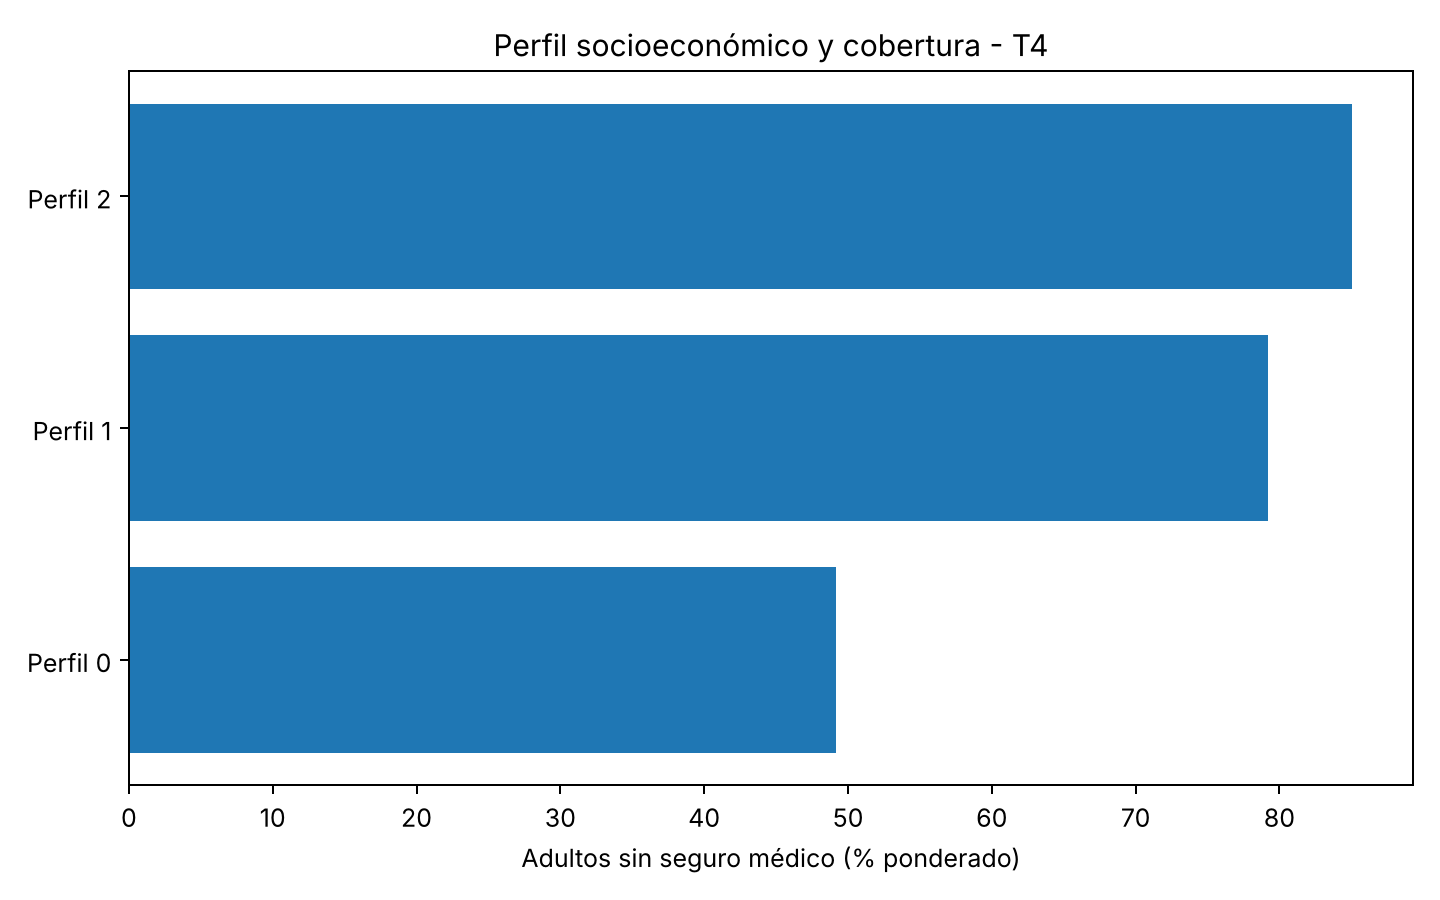

In [2]:
display(pd.read_csv(ejecutar.OUT/'seleccion_k.csv').round(3))
display(pd.read_csv(ejecutar.OUT/'resumen_perfiles.csv').round(2))
display(Image(filename=str(ejecutar.OUT/'perfiles_cobertura.png')))


## 3. Comparación predictiva
Se compara la clase mayoritaria con regresión logística, Random Forest e HistGradientBoosting. Se usa validación temporal (T1→T2 y T1+T2→T3) para seleccionar la configuración; T4 es el conjunto final de prueba. Los clusters se ajustan únicamente con el entrenamiento de cada división.

,modelo,con_cluster,auc_validacion,brier_validacion
0,Baseline,False,0.5000,0.3117
1,Baseline,True,0.5000,0.3117
2,Hist_Gradient_Boosting,False,0.8007,0.1620
3,Hist_Gradient_Boosting,True,0.8005,0.1621
4,Random_Forest,False,0.7982,0.1636
5,Random_Forest,True,0.8003,0.1635
6,Regresion_logistica,False,0.7976,0.1639
7,Regresion_logistica,True,0.7980,0.1637


,modelo,con_cluster,conjunto,n,prevalencia_sin_seguro_pct,accuracy,balanced_accuracy,precision,recall,f1,auc_roc,brier
1,Baseline,False,prueba_T4,11450,67.949,0.679,0.500,0.679,1.000,0.809,0.500,0.321
3,Regresion_logistica,False,prueba_T4,11450,67.949,0.743,0.666,0.773,0.879,0.823,0.784,0.171
5,Random_Forest,False,prueba_T4,11450,67.949,0.747,0.665,0.771,0.892,0.827,0.789,0.169
7,Hist_Gradient_Boosting,False,prueba_T4,11450,67.949,0.754,0.687,0.788,0.874,0.828,0.793,0.167
9,Baseline,True,prueba_T4,11450,67.949,0.679,0.500,0.679,1.000,0.809,0.500,0.321
11,Regresion_logistica,True,prueba_T4,11450,67.949,0.743,0.670,0.776,0.873,0.822,0.784,0.171
13,Random_Forest,True,prueba_T4,11450,67.949,0.747,0.671,0.775,0.884,0.826,0.787,0.169
15,Hist_Gradient_Boosting,True,prueba_T4,11450,67.949,0.754,0.686,0.786,0.876,0.829,0.792,0.167


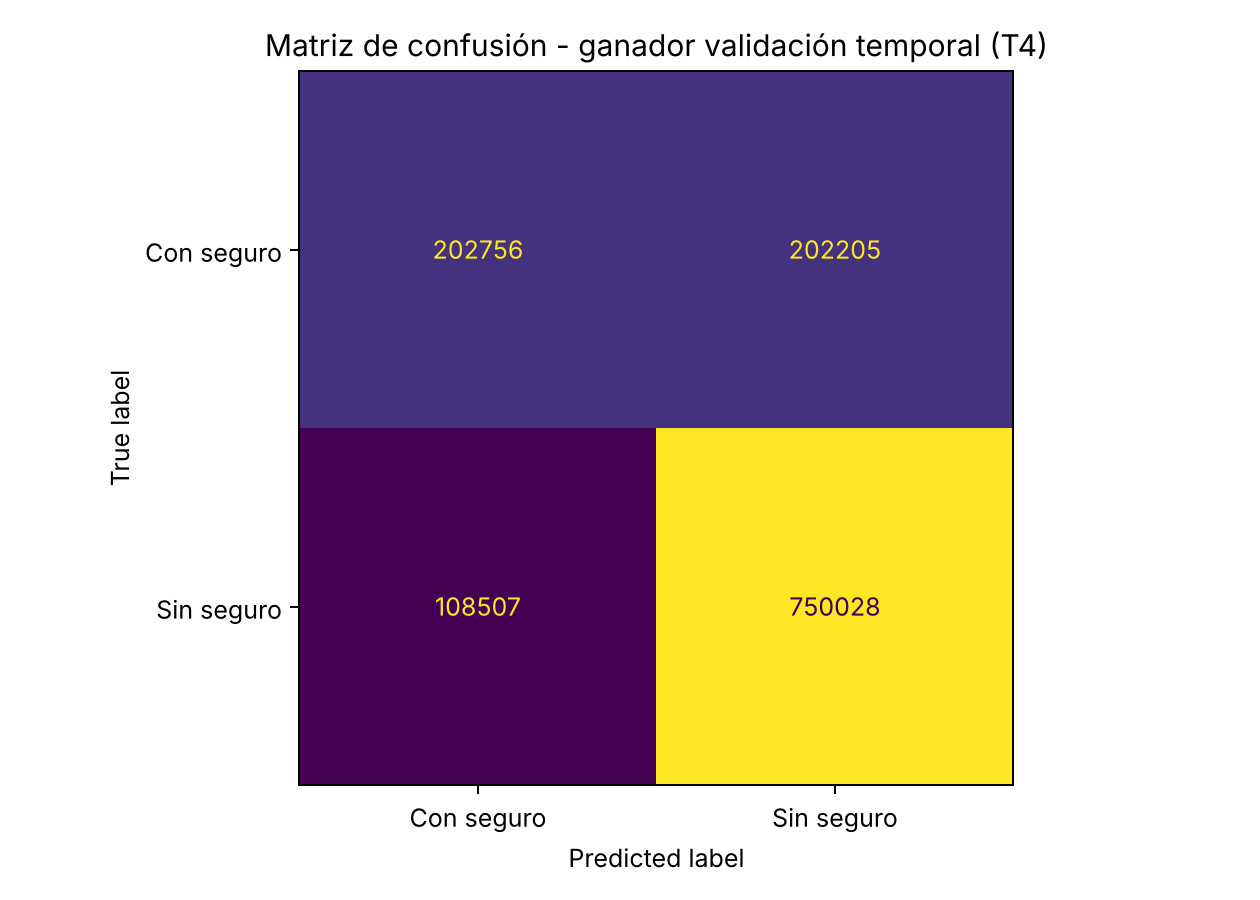

In [3]:
display(pd.read_csv(ejecutar.OUT/'ranking_validacion.csv').round(4))
display(pd.read_csv(ejecutar.OUT/'comparacion_test.csv').query("conjunto=='prueba_T4'").round(3))
display(Image(filename=str(ejecutar.OUT/'matriz_confusion.png')))


## 4. NBI como contexto territorial
Se cruzan indicadores de hogares del Censo 2022 con la cobertura de personas adultas EPHC 2024 a nivel departamental. No puede atribuirse a una persona el NBI de todo su departamento. Las cinco asociaciones son exploratorias.

,variable_nbi,rho,p_exploratorio,n_territorios
0,nbi_una_o_mas_pct,0.390,0.135,16
1,nbi_vivienda_pct,0.450,0.081,16
2,nbi_sanitaria_pct,0.190,0.481,16
3,nbi_educacion_pct,0.524,0.037,16
4,nbi_subsistencia_pct,0.529,0.035,16


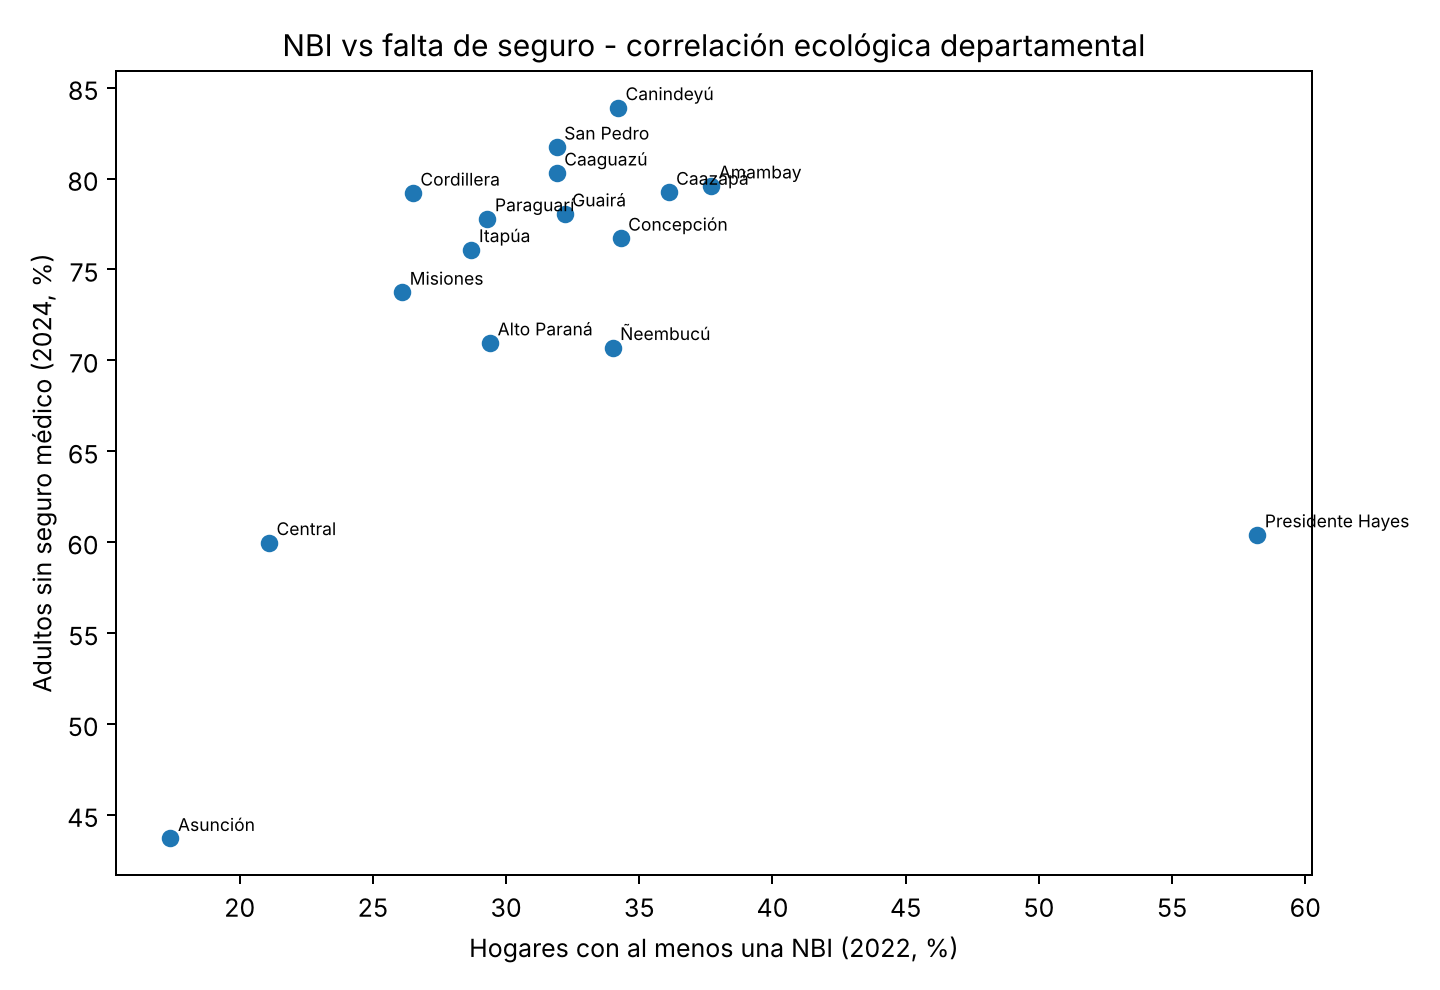

In [4]:
display(pd.read_csv(ejecutar.OUT/'correlaciones_nbi.csv').round(3))
display(Image(filename=str(ejecutar.OUT/'nbi_cobertura.png')))


## 5. Análisis complementarios (hiperparámetros, sobreajuste, interpretación y errores)
Se generan con `python -m src.fase3.complementos`, que reutiliza las funciones del pipeline oficial sin modificarlo.

**5.1 Búsqueda en grilla.** Se probaron 22 configuraciones (4 de regresión logística, 9 de Random Forest y 9 de HistGradientBoosting) con la misma validación temporal T1→T2 y T1+T2→T3, sin usar T4. La tabla muestra la mejor configuración de cada familia y la configuración oficial.

In [5]:
from pathlib import Path
COMP=ejecutar.OUT/'complementos'
if not (COMP/'grilla_hiperparametros.csv').exists():
    from src.fase3 import complementos
    complementos.main()
g=pd.read_csv(COMP/'grilla_hiperparametros.csv')
display(pd.concat([g.groupby('modelo').head(1).assign(fila='Mejor de la grilla'), g[g.es_oficial].assign(fila='Oficial')]).sort_values(['modelo','fila']).round(4))

,modelo,parametros,auc_T2,auc_T3,auc_validacion,es_oficial,fila
0,Hist_Gradient_Boosting,"{""learning_rate"": 0.06, ""max_leaf_nodes"": 7}",0.8092,0.7944,0.8018,False,Mejor de la grilla
4,Hist_Gradient_Boosting,"{""learning_rate"": 0.06, ""max_leaf_nodes"": 15}",0.8063,0.7950,0.8007,True,Oficial
9,Random_Forest,"{""max_depth"": 13, ""min_samples_leaf"": 10}",0.8072,0.7916,0.7994,False,Mejor de la grilla
12,Random_Forest,"{""max_depth"": 13, ""min_samples_leaf"": 35}",0.8058,0.7906,0.7982,True,Oficial
18,Regresion_logistica,"{""C"": 0.01}",0.8070,0.7885,0.7977,False,Mejor de la grilla
20,Regresion_logistica,"{""C"": 1.0}",0.8068,0.7884,0.7976,True,Oficial


**5.2 Brecha de sobreajuste.** AUC ponderado en entrenamiento (T1 a T3), validación temporal y prueba (T4).

In [6]:
display(pd.read_csv(COMP/'brecha_sobreajuste.csv').round(4))

,modelo,auc_entrenamiento,auc_validacion,auc_prueba_T4,brecha_entrenamiento_validacion,brecha_validacion_prueba
0,Regresion_logistica,0.8038,0.7976,0.7843,0.0061,0.0133
1,Random_Forest,0.8299,0.7982,0.7889,0.0317,0.0092
2,Hist_Gradient_Boosting,0.8254,0.8007,0.7925,0.0247,0.0082


**5.3 Importancia de variables.** Caída del AUC en T4 al desordenar cada variable (10 repeticiones), para el modelo ganador y para la regresión logística. Luego, la regresión logística interpretable (OR con errores robustos por UPM, sobre T1 a T3).

In [7]:
display(pd.read_csv(COMP/'importancia_permutacion.csv').round(4))
display(pd.read_csv(COMP/'importancia_permutacion_logistica.csv').round(4))
display(pd.read_csv(COMP/'logistica_or.csv',index_col=0).drop(index='Intercept').round(3))

,variable,caida_auc,desvio
0,log_ingreso,0.1339,0.0079
1,anios_estudio,0.0811,0.0029
2,edad,0.0488,0.0026
3,departamento,0.0163,0.0010
4,area,0.0013,0.0003
5,sexo,0.0008,0.0003


,variable,caida_auc,desvio
0,anios_estudio,0.0993,0.0035
1,log_ingreso,0.0953,0.0063
2,edad,0.0453,0.0030
3,departamento,0.0160,0.0013
4,area,0.0006,0.0001
5,sexo,-0.0000,0.0000


,OR,IC95_inf,IC95_sup,p
"C(sexo, Treatment('Hombre'))[T.Mujer]",0.998,0.948,1.050,0.936
"C(area, Treatment('Urbana'))[T.Rural]",1.144,1.029,1.271,0.013
"C(departamento, Treatment('Asunción'))[T.Alto Paraná]",1.671,1.407,1.985,0.000
"C(departamento, Treatment('Asunción'))[T.Amambay]",3.175,2.387,4.224,0.000
"C(departamento, Treatment('Asunción'))[T.Caaguazú]",2.039,1.620,2.566,0.000
"C(departamento, Treatment('Asunción'))[T.Caazapá]",1.923,1.539,2.402,0.000
"C(departamento, Treatment('Asunción'))[T.Canindeyú]",2.960,2.332,3.757,0.000
"C(departamento, Treatment('Asunción'))[T.Central]",1.299,1.129,1.494,0.000
"C(departamento, Treatment('Asunción'))[T.Concepción]",1.681,1.322,2.137,0.000
"C(departamento, Treatment('Asunción'))[T.Cordillera]",2.445,1.984,3.013,0.000


**5.4 Análisis de errores.** Matriz de confusión ponderada (porcentaje de la población de T4), errores por subgrupo y perfil del 1 % de casos peor predichos.

In [8]:
display(pd.read_csv(COMP/'matriz_confusion_pct.csv').round(2))
display(pd.read_csv(COMP/'errores_subgrupos.csv').round(1))
display(pd.read_csv(COMP/'perfil_peores_casos.csv',index_col=0).round(2))
display(pd.read_csv(COMP/'tipo_seguro_falsos_positivos.csv',index_col=0).round(1))
display(pd.read_csv(COMP/'ejemplos_peores_casos.csv').round(2))

,tipo,peso
0,FN,8.59
1,FP,16.00
2,VN,16.05
3,VP,59.36


,variable,categoria,n,sin_seguro_pct,acierto_pct,detecta_sin_seguro_pct,detecta_con_seguro_pct
0,area,Rural,5085,82.5,85.0,96.5,30.8
1,area,Urbana,6365,61.8,71.3,82.2,53.8
2,sexo,Hombre,5653,68.2,74.2,87.0,46.7
3,sexo,Mujer,5797,67.7,76.7,87.8,53.4
4,grupo_edad,18-29,3030,73.7,77.0,93.1,31.9
5,grupo_edad,30-44,3503,66.1,74.1,83.5,56.0
6,grupo_edad,45-59,2418,69.0,77.0,86.9,54.9
7,grupo_edad,60+,2499,60.9,73.3,84.2,56.2
8,quintil_muestra,Q1,2284,93.3,93.3,100.0,0.0
9,quintil_muestra,Q2,2283,84.5,84.5,99.8,0.9


,n,edad_media,anios_estudio_media,ingreso_mediano,rural_pct,mujer_pct,prob_media
Todos T4,11450.0,43.68,9.45,1577266.94,44.41,50.63,0.71
Peores FP (tenía seguro),115.0,45.08,6.18,768044.24,71.30,41.74,0.94
Peores FN (no tenía seguro),0.0,NaN,NaN,NaN,NaN,NaN,NaN


,peores_FP,todos_FP
S01A,,
IPS,75.7,80.0
Privado familiar,12.2,10.9
Privado individual,1.7,1.7
Privado laboral,0.9,2.3
Sanidad Militar,6.1,1.9
Sanidad Policial,3.5,3.2


,tipo,prob,edad,sexo,area,departamento,anios_estudio,ingreso_per_capita,S01A
0,FP,0.99,19,Mujer,Rural,Concepción,12.0,158066.16,6
1,FP,0.99,53,Mujer,Rural,San Pedro,6.0,400833.22,4
2,FP,0.98,58,Hombre,Rural,San Pedro,6.0,400833.22,4
3,FP,0.98,20,Hombre,Urbana,San Pedro,9.0,815849.88,4
4,FP,0.98,66,Hombre,Rural,Cordillera,0.0,172027.36,5
5,FP,0.98,18,Hombre,Urbana,Misiones,10.0,476903.34,1
6,FP,0.98,18,Hombre,Urbana,Misiones,10.0,476903.34,1
7,FP,0.97,65,Mujer,Rural,San Pedro,2.0,371848.34,1
8,FP,0.97,21,Hombre,Rural,San Pedro,12.0,780237.23,1
9,FP,0.97,60,Mujer,Rural,Cordillera,2.0,172027.36,5


## 6. Conclusión
**El nuevo objetivo de ausencia de cobertura es considerablemente más predecible que la condición de enfermedad reciente** en los respectivos experimentos (no son comparaciones de la misma variable objetivo ni población). La clasificación por Gradient Boosting superó a su baseline con AUC-ROC cercano a 0,793 en T4. Los perfiles evidencian desigualdades descriptivas, pero no mejoraron claramente la predicción y su separación/estabilidad es limitada. Las asociaciones del NBI no superan correcciones por comparaciones múltiples. No interpretar los hallazgos como efectos causales ni criterios para denegar prestaciones.